# Cài đặt thuật toán PLA bằng NumPy

*Bài 4, mục 4.2.3 e).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def predict(w, Xbar):
    """Dự đoán nhãn +1/-1 cho mỗi hàng của Xbar (quy ước sgn(0) = 1)."""
    return np.where(Xbar @ w >= 0, 1, -1)


def perceptron(Xbar, y, w_init, max_iter=1000):
    """Thuật toán PLA. Xbar: (N, d+1) đã thêm cột 1; y: nhãn +1/-1."""
    w = w_init.copy()
    for t in range(max_iter):
        sai = np.where(predict(w, Xbar) != y)[0]   # chỉ số các điểm bị phân loại sai
        if len(sai) == 0:                          # không còn điểm sai -> dừng
            return w, t
        i = np.random.choice(sai)                  # chọn ngẫu nhiên một điểm sai
        w = w + y[i] * Xbar[i]                     # cập nhật w <- w + y_i x_i
    return w, max_iter

## 1. Dữ liệu tách biệt tuyến tính

Hai nhóm 10 điểm sinh ngẫu nhiên theo phân phối chuẩn.

w = [ 0.6864918  -1.87365142  0.18846955] - số lần cập nhật: 3
Số điểm sai: 0


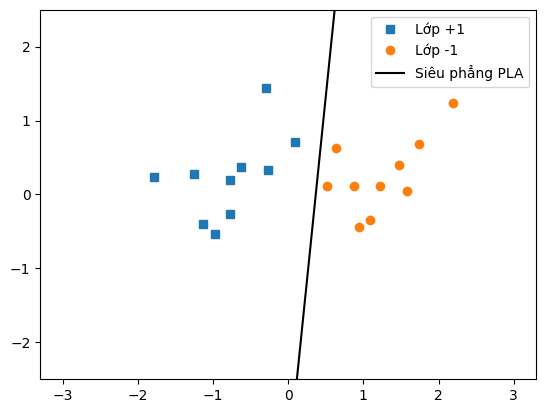

In [2]:
np.random.seed(2)
means = [[-1, 0], [1, 0]]
cov = [[.3, .2], [.2, .3]]
N = 10
X0 = np.random.multivariate_normal(means[0], cov, N)   # lớp +1
X1 = np.random.multivariate_normal(means[1], cov, N)   # lớp -1
X = np.concatenate((X0, X1), axis=0)
y = np.concatenate((np.ones(N), -1 * np.ones(N)))
Xbar = np.concatenate((np.ones((2 * N, 1)), X), axis=1)

w, so_lan = perceptron(Xbar, y, np.random.randn(3))
print('w =', w, '- số lần cập nhật:', so_lan)
print('Số điểm sai:', np.sum(predict(w, Xbar) != y))

xs = np.array([-3, 3])
plt.plot(X0[:, 0], X0[:, 1], 's', label='Lớp +1')
plt.plot(X1[:, 0], X1[:, 1], 'o', label='Lớp -1')
plt.plot(xs, -(w[0] + w[1] * xs) / w[2], 'k-', label='Siêu phẳng PLA')
plt.ylim(-2.5, 2.5); plt.legend(); plt.show()

## 2. Dữ liệu XOR không tách biệt tuyến tính

PLA không bao giờ hết điểm sai, chỉ dừng khi hết `max_iter`.

In [3]:
X_xor = np.array([[1, 0, 0], [1, 1, 1], [1, 0, 1], [1, 1, 0]], dtype=float)
y_xor = np.array([-1, -1, 1, 1])
w, so_lan = perceptron(X_xor, y_xor, np.zeros(3), max_iter=1000)
print('XOR: số lần lặp =', so_lan, '- số điểm sai:', np.sum(predict(w, X_xor) != y_xor))

XOR: số lần lặp = 1000 - số điểm sai: 2
